In [14]:
   import sys; from pathlib import Path
   import pandas as pd
   import matplotlib.pyplot as plt
   import seaborn as sns
   sys.path.insert(0, str(Path.cwd().parent))
   from src.data import build_table
   df = build_table()

In [3]:
df.columns.tolist()

['match_id',
 'zone',
 'seats',
 'season_tickets',
 'season',
 'match_date',
 'time',
 'weekday',
 'opponent',
 'opponent_khl',
 'sales_open',
 'part',
 'hour',
 'month',
 'is_weekend',
 'is_test',
 'capacity',
 'sold_as_of',
 'sold_last_7d',
 'sold_last_14d',
 'sales_started',
 'days_to_match',
 'days_since_open',
 'tickets_total']

In [4]:
   train = df[df["is_test"] == 0].copy()
   train.shape

(680, 24)

In [8]:
print(df.shape)
df.isna().sum()

(816, 24)


match_id             0
zone                 0
seats                0
season_tickets       0
season               0
match_date           0
time                 0
weekday              0
opponent             0
opponent_khl         0
sales_open           0
part                 0
hour                 0
month                0
is_weekend           0
is_test              0
capacity             0
sold_as_of           0
sold_last_7d         0
sold_last_14d        0
sales_started        0
days_to_match        0
days_since_open      0
tickets_total      136
dtype: int64

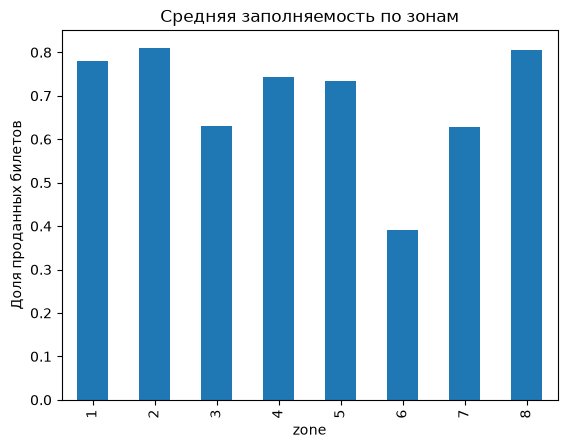

In [6]:
   import matplotlib.pyplot as plt
   train["fill_rate"] = train["tickets_total"] / train["capacity"]
   train.groupby("zone")["fill_rate"].mean().plot(kind="bar")
   plt.title("Средняя заполняемость по зонам")
   plt.ylabel("Доля проданных билетов")
   plt.show()

**Вывод:** зоны 1, 2 и 8 заполняются лучше всего (около 80%), а зона 6 — хуже всех (около 39%), заметно ниже остальных.

In [7]:
train.groupby("zone")[["seats", "season_tickets", "capacity", "tickets_total"]].mean().round(0)

,seats,season_tickets,capacity,tickets_total
zone,,,,
1,1141.0,545.0,596.0,465.0
2,528.0,148.0,380.0,308.0
3,1386.0,385.0,1001.0,633.0
4,1340.0,287.0,1053.0,782.0
5,1511.0,466.0,1044.0,767.0
6,1448.0,200.0,1248.0,487.0
7,1434.0,186.0,1248.0,781.0
8,682.0,120.0,562.0,450.0


**Вывод:** зона 6 заполняется хуже всех (около 39%). При этом по вместимости она не отличается от зоны 7 (по 1248 мест), но продаёт в среднем 487 билетов против 781. Причина по данным неясна (нет информации о ценах и расположении)Больше всего билетов в абсолютных числах продают зоны 4, 5 и 7 (около 770-780 на матч).

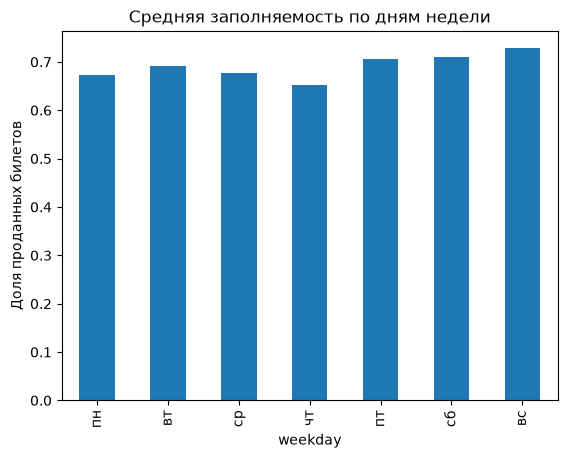

weekday
пн    12
вт     9
ср    15
чт    13
пт    11
сб    13
вс    12
Name: match_id, dtype: int64


In [9]:
days = {1: "пн", 2: "вт", 3: "ср", 4: "чт", 5: "пт", 6: "сб", 7: "вс"}

by_day = train.groupby("weekday")["fill_rate"].mean()
by_day.index = by_day.index.map(days)
by_day.plot(kind="bar")
plt.title("Средняя заполняемость по дням недели")
plt.ylabel("Доля проданных билетов")
plt.show()

# сколько матчей в каждый день, чтобы не делать выводы по 1-2 матчам
print(train.groupby("weekday")["match_id"].nunique().rename(index=days))

**Вывод:** день недели влияет на заполняемость слабо: все дни лежат в диапазоне примерно 65-73%. Лучше всего заполняются выходные и пятница (воскресенье около 73%, суббота и пятница около 71%), хуже всего четверг (около 65%). 

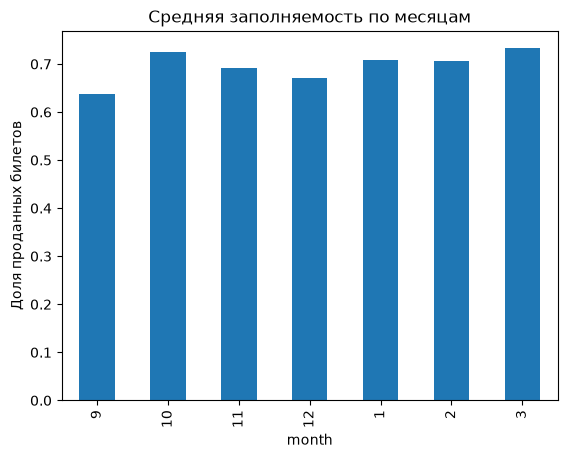

In [10]:
by_month = train.groupby("month")["fill_rate"].mean()
by_month = by_month.sort_index(key=lambda m: (m - 9) % 12)
by_month.plot(kind="bar")
plt.title("Средняя заполняемость по месяцам")
plt.ylabel("Доля проданных билетов")
plt.show()

**Вывод:** заполняемость по месяцам колеблется в узком диапазоне, примерно 64-73%, явного роста или падения в течение сезона нет. Надёжнее всего выделяется сентябрь (около 64%, 17 матчей): возможно, в начале сезона спрос ещё не разогрет, и здесь у клуба есть запас для маркетинга. Лучший из месяцев с достаточным числом матчей — октябрь (около 73%, 20 матчей). Март показывает около 73%, но матчей в нём всего 2, поэтому вывод по нему ненадёжен.

In [12]:
opp = (train.groupby("opponent")
       .agg(fill=("fill_rate", "mean"), matches=("match_id", "nunique"))
       .sort_values("fill"))
print(len(opp), "соперников")
opp

22 соперников


,fill,matches
opponent,,
Сочи,0.589308,3
Амур,0.595521,5
Динамо Мск,0.634847,3
Динамо Мн,0.649152,3
Адмирал,0.671014,5
Нефтехимик,0.682135,5
СКА,0.685823,3
Ак Барс,0.692530,5
Сибирь,0.695850,4


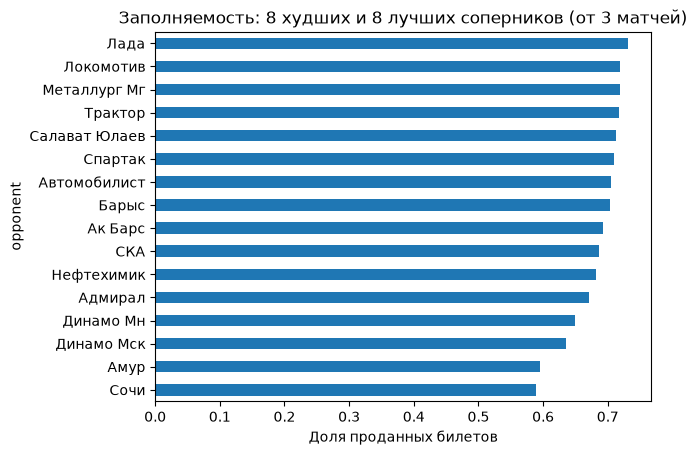

In [15]:
opp_ok = opp[opp["matches"] >= 3]   # только соперники, с которыми минимум 3 матча
top_bottom = pd.concat([opp_ok.head(8), opp_ok.tail(8)])
top_bottom["fill"].plot(kind="barh")
plt.title("Заполняемость: 8 худших и 8 лучших соперников (от 3 матчей)")
plt.xlabel("Доля проданных билетов")
plt.show()

**Вывод:** соперник влияет на заполняемость сильнее, чем день недели или месяц: среди соперников с 3+ матчами разброс составляет около 14 процентных пунктов (от ~59% до ~73%). Хуже всего заполняются матчи с Сочи и Амуром (около 59-60%), а также с московским и минским «Динамо» (около 63-65%); лучше всего с Ладой, Локомотивом, Металлургом Мг и Трактором (около 72-73%). Громкие соперники (СКА, Ак Барс) оказались в середине списка, то есть «имя» соперника само по себе спрос не гарантирует. Матчей с каждым соперником немного (3-7), поэтому различия между близкими соперниками могут быть случайными. Кроме того, часть эффекта может объясняться не самим соперником, а днём недели или месяцем, на которые пришлись его матчи.

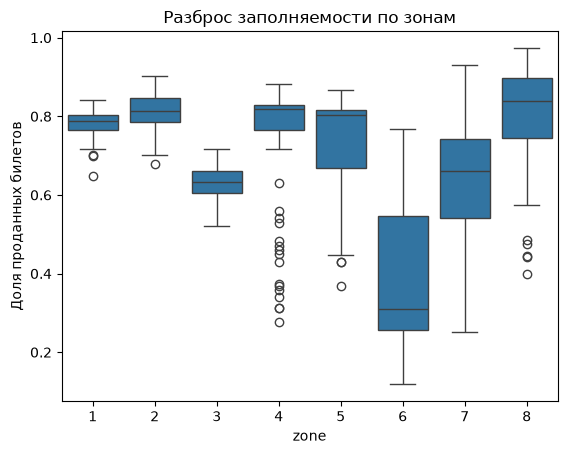

In [16]:
sns.boxplot(data=train, x="zone", y="fill_rate")
plt.title("Разброс заполняемости по зонам")
plt.ylabel("Доля проданных билетов")
plt.show()

**Вывод:** по стабильности зоны делятся на три группы. Стабильны зоны 1, 2 и 3 (заполняемость от матча к матчу почти не меняется; в зонах 1 и 2 она высокая, около 79-81%, а в зоне 3 около 63%). Зона 4 обычно заполнена хорошо (около 82%), но в ней больше всего выбросов вниз: примерно в дюжине матчей продажи упали до 28-63%. Больше всего разброс в зонах 6 и 7: в зоне 6 типичная заполняемость около 31%, но отдельные матчи доходят до 77%, в зоне 7 разброс от 25% до 93%. Так как зоны 6 и 7 вместительные (по 1248 мест для разовых билетов), именно в них модели будет труднее всего и именно там возможна наибольшая ошибка в штуках.

In [ ]:
m = (train.groupby(["match_id", "match_date", "opponent", "weekday", "month", "season"])
     .agg(sold=("tickets_total", "sum"), cap=("capacity", "sum"))
     .reset_index())
m["fill_rate"] = m["sold"] / m["cap"]
m = m.sort_values("fill_rate")
m.head(10)[["match_date", "opponent", "weekday", "month", "season", "fill_rate"]]

In [ ]:
m.tail(10)[["match_date", "opponent", "weekday", "month", "season", "fill_rate"]]

In [19]:
weak = m.head(10)
strong = m.tail(10)

print("Слабые, по сезонам:")
print(weak["season"].value_counts())
print("\nСлабые, по дням недели:")
print(weak["weekday"].value_counts())
print("\nСлабые, по соперникам:")
print(weak["opponent"].value_counts().head())

print("\nСильные, по сезонам:")
print(strong["season"].value_counts())

Слабые, по сезонам:
season
2024/25    4
2023/24    4
2025/26    2
Name: count, dtype: int64

Слабые, по дням недели:
weekday
3    3
1    3
4    3
5    1
Name: count, dtype: int64

Слабые, по соперникам:
opponent
Амур          4
Динамо Мск    1
Адмирал       1
Нефтехимик    1
Динамо Мн     1
Name: count, dtype: int64

Сильные, по сезонам:
season
2025/26    7
2023/24    3
Name: count, dtype: int64


**Вывод:** среди 10 самых слабых матчей нет ни одного матча выходного дня (понедельник, среда и четверг по 3 матча, пятница 1), при том что будни составляют около 70% всех матчей. Кроме того, 4 из 10 самых слабых матчей — с Амуром (всего с ним было 5 матчей). Среди 10 самых сильных матчей 7 приходятся на сезон 2025/26 и ни одного на 2024/25, то есть спрос в текущем сезоне, возможно, выше. Выборка из 10 матчей небольшая, поэтому эти закономерности стоит проверять на модели.

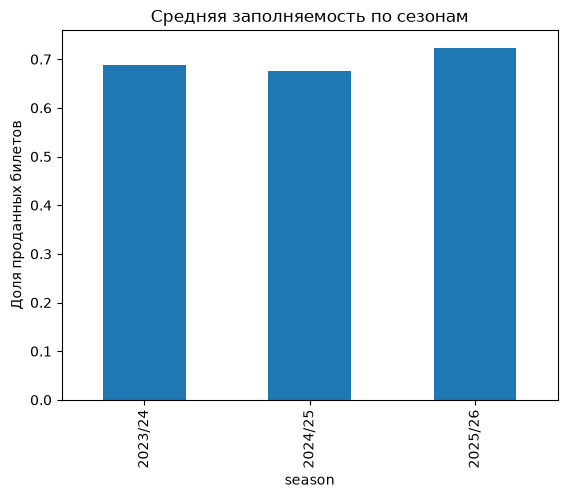

In [20]:
   train.groupby("season")["fill_rate"].mean().plot(kind="bar")
   plt.title("Средняя заполняемость по сезонам")
   plt.ylabel("Доля проданных билетов")
   plt.show()

**Вывод:** заполняемость по сезонам различается слабо: 2025/26 около 72%, 2023/24 около 69%, 2024/25 около 67-68%. Текущий сезон немного выше остальных, что согласуется с тем, что 7 из 10 самых сильных матчей пришлись на него. Но в train от сезона 2025/26 только 17 матчей (первая половина сезона), поэтому вывод о росте спроса предварительный. Для модели сезон полезен как признак, но большую часть разброса он не объясняет.